# Mini-Project 2: Solar Micro-Grid Dispatch Planner

**Scenario.** A rural health centre in Kasese runs a micro-grid. Each day the energy from solar panels (**x**, kWh)
and batteries (**y**, kWh) must satisfy two demand equations:

$$3x + 2y = D_1 \quad\text{(daytime load, kWh)}$$
$$4x + y = D_2 \quad\text{(critical-equipment load, kWh)}$$

The reusable code lives in `src/microgrid.py`. This notebook runs each task.

In [1]:
# --- Imports ----------------------------------------------------------------------

# statistics: built-in mean / variance / stdev
import statistics

# timeit: built-in tool that times how long a piece of code takes
import timeit

# numpy: arrays and maths
import numpy as np

# pandas: tables
import pandas as pd

# matplotlib: charts
import matplotlib.pyplot as plt

# Our own code from src/microgrid.py
from src.microgrid import (
    MicroGrid,              # the 2-source grid (solar + battery)
    HybridMicroGrid,        # extension: adds a diesel generator
    read_positive_number,   # asks for a number until it is valid
    generate_demand_csv,    # makes 30 days of demand data
    load_demand_csv,        # reads that CSV back
    SOLAR_PRICE_UGX,        # 150 UGX per kWh
    BATTERY_PRICE_UGX,      # 450 UGX per kWh
)

SEED = 42
CSV_PATH = "data/microgrid_demand.csv"

BLUE, ORANGE, INK = "#2a78d6", "#eb6834", "#3b3a37"
SOLAR_COLOUR, BATTERY_COLOUR = "#eda100", "#4a3aa7"
plt.rcParams.update({"axes.spines.top": False, "axes.grid": True, "grid.alpha": 0.3})

## Task 1 – The `MicroGrid` class and whether the system is well-posed

In [2]:
grid = MicroGrid()          # uses the matrix [[3, 2], [4, 1]] by default
print(grid)
print("Coefficient matrix A:\n", grid.coefficients)
print("Determinant:     ", round(grid.determinant(), 4))
print("Condition number:", round(grid.condition_number(), 4))
print("Well-posed?      ", grid.is_well_posed())

# Example day: D1 = 120 kWh, D2 = 100 kWh
solar, battery = grid.solve_day(120, 100)
print(f"\nExample: D1=120, D2=100 -> solar x = {solar:.2f} kWh, battery y = {battery:.2f} kWh")

MicroGrid(sources=['solar', 'battery'])
Coefficient matrix A:
 [[3. 2.]
 [4. 1.]]
Determinant:      -5.0
Condition number: 5.8284
Well-posed?       True

Example: D1=120, D2=100 -> solar x = 16.00 kWh, battery y = 36.00 kWh


**What these numbers mean**

* **Determinant = 3×1 − 2×4 = −5.** It is not zero, so the two equations are independent: for any pair of demands
  there is **exactly one** (x, y). If it were 0, the two lines would be parallel (no answer) or identical
  (endless answers). The minus sign has no practical meaning here.
* **Condition number ≈ 5.8.** It is how much a small relative error in D1/D2 can be magnified in x and y, at most.
  A value near 1 is perfect, and values in the thousands would be alarming. At about 6, a 1% meter error in the
  demand can shift the answer by at most about 6%, so the system is **well-conditioned** and safe to solve.

## Task 2 – Two input modes

### (a) Interactive input with validation
`read_positive_number()` keeps asking until the text is a number ≥ 0. It rejects empty text, words and negatives.
Because the notebook must run top to bottom *without a person typing*, the real `input()` is behind a switch.
Set `INTERACTIVE = True` to try it yourself. With it off, we feed in a fake typist to show the validation working.

In [3]:
INTERACTIVE = False    # change to True to type the demands yourself

if INTERACTIVE:
    d1 = read_positive_number("Daytime load D1 (kWh): ")
    d2 = read_positive_number("Critical load D2 (kWh): ")
else:
    # A pretend user who first types nothing, then "abc", then -5, then a valid 120
    fake_typing = iter(["", "abc", "-5", "120", "100"])
    fake_input = lambda prompt: next(fake_typing)   # lambda = a tiny one-line function
    d1 = read_positive_number("D1: ", input_function=fake_input)
    d2 = read_positive_number("D2: ", input_function=fake_input)

print(f"Accepted D1 = {d1}, D2 = {d2} -> (solar, battery) = {grid.solve_day(d1, d2)}")

  Please type a value - it cannot be empty.
  'abc' is not a number. Try again.
  Demand cannot be negative. Try again.
Accepted D1 = 120.0, D2 = 100.0 -> (solar, battery) = (16.0, 36.0)


### (b) Loading 30 days of demand from a CSV

We generate the CSV ourselves with a **seeded** random generator: a weekly wave (busier weekdays at the clinic) plus
random noise, so the data looks realistic and comes out identical on every run.

In [4]:
generate_demand_csv(CSV_PATH, days=30, seed=SEED)
demands = load_demand_csv(CSV_PATH)          # shape (2, 30): row 0 = D1, row 1 = D2
print("Shape of demand matrix:", demands.shape)
pd.read_csv(CSV_PATH).head(7)                # first week of the file

Shape of demand matrix: (2, 30)


,day,d1_kwh,d2_kwh
0,1,122.44,167.12
1,2,123.41,132.81
2,3,140.63,132.19
3,4,134.03,124.96
4,5,97.88,142.07
5,6,94.96,147.06
6,7,109.30,129.38


## Task 3 – Solve all 30 days: loop vs vectorised

In [5]:
usage_loop = grid.solve_days_loop(demands)            # 30 separate solve() calls
usage_vec = grid.solve_days_vectorised(demands)       # 1 call with a 2 x 30 right-hand side
print("Same answers?", np.allclose(usage_loop, usage_vec))

REPEATS = 500
loop_seconds = timeit.timeit(lambda: grid.solve_days_loop(demands), number=REPEATS)
vec_seconds = timeit.timeit(lambda: grid.solve_days_vectorised(demands), number=REPEATS)
print(f"Loop:       {loop_seconds / REPEATS * 1e6:8.1f} microseconds per 30 days")
print(f"Vectorised: {vec_seconds / REPEATS * 1e6:8.1f} microseconds per 30 days")
print(f"Vectorised is about {loop_seconds / vec_seconds:.0f}x faster")

Same answers? True


Loop:         2723.9 microseconds per 30 days
Vectorised:    200.2 microseconds per 30 days
Vectorised is about 14x faster


**Comment.** Both give identical answers, but the vectorised call is many times faster. Each `solve()` call has a fixed
overhead (checking inputs, factorising the matrix, moving between Python and compiled code). The loop pays it 30 times.
The vectorised call pays it once and then solves all 30 right-hand sides inside fast compiled code. For 30 days both
take well under a second, so it doesn't matter here, but for a year of hourly data (8,760 columns) the gap would.

## Task 4 – Infeasible days

A negative x or y is physically impossible: panels can't "un-produce" energy.
Solving the equations gives negatives when D2 is too high or too low compared with D1
(x = (2·D2 − D1)/5 and y = (4·D1 − 3·D2)/5).

In [6]:
bad_days = grid.infeasible_days(usage_vec)            # True/False for each day
print("Infeasible days:", [int(d) for d in np.where(bad_days)[0] + 1], f"({bad_days.sum()} of 30)")

pd.DataFrame({
    "D1": demands[0, bad_days], "D2": demands[1, bad_days],
    "solar x": usage_vec[0, bad_days], "battery y": usage_vec[1, bad_days],
}, index=np.where(bad_days)[0] + 1).rename_axis("day").round(2)

Infeasible days: [1, 5, 6, 28] (4 of 30)


,D1,D2,solar x,battery y
day,,,,
1,122.44,167.12,42.36,-2.32
5,97.88,142.07,37.25,-6.94
6,94.96,147.06,39.83,-12.27
28,111.20,153.51,39.16,-3.15


**Our handling strategy: non-negative least squares (NNLS).** Simply clipping the negative number to 0 would break
*both* equations without telling us by how much. `scipy.optimize.nnls` instead finds the non-negative (x, y) that comes
**as close as possible** to meeting both demands, and reports the **shortfall** (in kWh) so the manager knows the gap
(for example to cover with a generator or by switching off non-critical load).

In [7]:
usage, report = grid.solve_days_safely(demands)       # usage with bad days re-solved by NNLS

pd.DataFrame([{
    "day": r["day"],
    "original (x, y)": np.round(r["original"], 2),
    "fixed (x, y)": np.round(r["fixed"], 2),
    "shortfall kWh": round(r["shortfall_kwh"], 2),
} for r in report]).set_index("day")

,"original (x, y)","fixed (x, y)",shortfall kWh
day,,,
1,"[42.36, -2.32]","[41.43, 0.0]",2.32
5,"[37.25, -6.94]","[34.48, 0.0]",6.94
6,"[39.83, -12.27]","[34.92, 0.0]",12.27
28,"[39.16, -3.15]","[37.91, 0.0]",3.15


## Task 5 – Which source is more volatile?

In [8]:
solar_kwh, battery_kwh = usage[0], usage[1]      # the two rows, after fixing bad days

volatility = pd.DataFrame({
    source: {
        "mean (kWh)": statistics.mean(values),
        "variance (kWh²)": statistics.variance(values),
        "std dev (kWh)": statistics.stdev(values),
        "CV (std / mean)": statistics.stdev(values) / statistics.mean(values),
    }
    for source, values in [("solar", list(solar_kwh)), ("battery", list(battery_kwh))]
})
volatility.round(3)

,solar,battery
mean (kWh),30.300,15.141
variance (kWh²),23.482,112.215
std dev (kWh),4.846,10.593
CV (std / mean),0.160,0.700


The **battery** is the more volatile source, both in absolute terms (bigger standard deviation) and relative to its size
(CV). This makes sense: x = (2·D2 − D1)/5 but y = (4·D1 − 3·D2)/5, so the battery's answer multiplies the
demand noise by bigger numbers (4 and 3 against 2 and 1). The battery absorbs the day-to-day swings.

## Task 6 – Energy cost
Solar costs **UGX 150/kWh**, battery **UGX 450/kWh** (illustrative).

In [9]:
daily_cost = MicroGrid.daily_cost(solar_kwh, battery_kwh)     # one cost per day, UGX
print(f"Average daily cost: UGX {daily_cost.mean():,.0f}")
print(f"Cheapest day:       UGX {daily_cost.min():,.0f} (day {daily_cost.argmin() + 1})")
print(f"Most expensive day: UGX {daily_cost.max():,.0f} (day {daily_cost.argmax() + 1})")
print(f"Monthly (30-day) cost: UGX {daily_cost.sum():,.0f}")

Average daily cost: UGX 11,358
Cheapest day:       UGX 5,172 (day 5)
Most expensive day: UGX 22,118 (day 23)
Monthly (30-day) cost: UGX 340,752


## Task 7 – Stacked bar chart with daily cost on a second axis

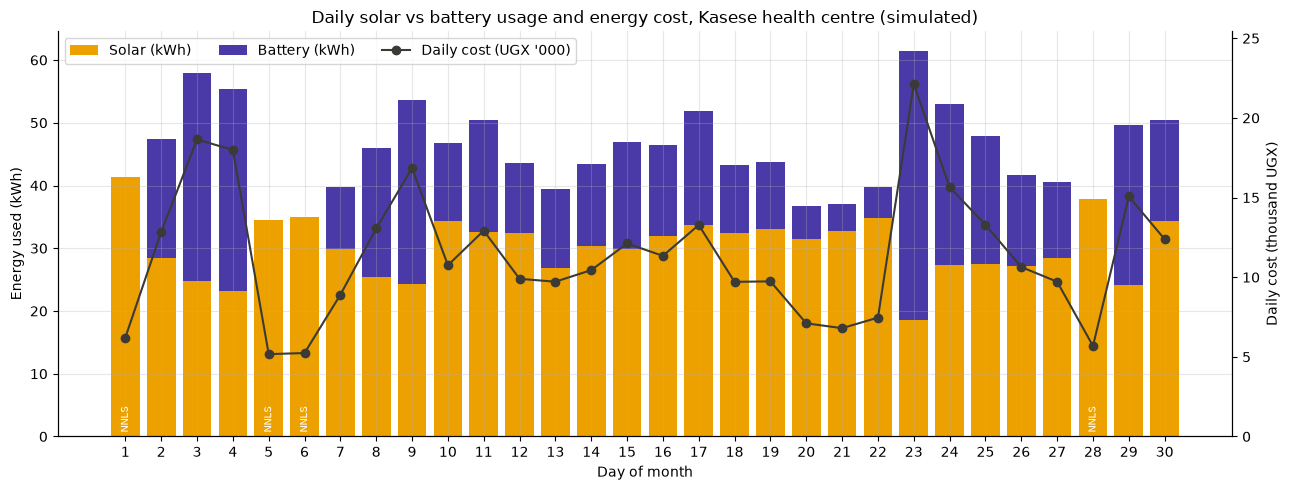

In [10]:
days = np.arange(1, 31)
fig, ax = plt.subplots(figsize=(13, 5))

# Stacked bars: battery bars sit on top of the solar bars (bottom=solar_kwh)
ax.bar(days, solar_kwh, color=SOLAR_COLOUR, label="Solar (kWh)")
ax.bar(days, battery_kwh, bottom=solar_kwh, color=BATTERY_COLOUR, label="Battery (kWh)")
ax.set_xlabel("Day of month")
ax.set_ylabel("Energy used (kWh)")
ax.set_xticks(days)

# Mark the days that were fixed with NNLS
for r in report:
    ax.annotate("NNLS", (r["day"], 1), ha="center", fontsize=7, color="white", rotation=90)

# twinx() makes a second y-axis on the right that shares the same x-axis
ax_cost = ax.twinx()
ax_cost.plot(days, daily_cost / 1000, "o-", color=INK, label="Daily cost (UGX '000)")
ax_cost.set_ylabel("Daily cost (thousand UGX)")
ax_cost.set_ylim(0, daily_cost.max() / 1000 * 1.15)
ax_cost.grid(False)

# One legend combining both axes
bars, bar_labels = ax.get_legend_handles_labels()
line, line_labels = ax_cost.get_legend_handles_labels()
ax.legend(bars + line, bar_labels + line_labels, loc="upper left", ncol=3)
ax.set_title("Daily solar vs battery usage and energy cost, Kasese health centre (simulated)")
fig.tight_layout()
plt.show()

## Extension

### (a) `HybridMicroGrid`: adding a diesel generator
`HybridMicroGrid` **inherits** from `MicroGrid`, so it reuses the checks, solving and NNLS code. It only changes the
matrix. Our third constraint (our choice) is the **total daily energy**: x + y + z = D3.

In [11]:
hybrid = HybridMicroGrid()
print(hybrid)
print("A =\n", hybrid.coefficients)
print("Determinant:", round(hybrid.determinant(), 3), "| condition number:", round(hybrid.condition_number(), 2))

# Day 2 demands from the CSV, plus a total daily demand D3 = 60 kWh
x, y, z = hybrid.solve_day(demands[0, 1], demands[1, 1], 60)
print(f"Day 2 with diesel: solar {x:.2f}, battery {y:.2f}, diesel {z:.2f} kWh")

HybridMicroGrid(sources=['solar', 'battery', 'diesel'])
A =
 [[3. 2. 0.]
 [4. 1. 0.]
 [1. 1. 1.]]
Determinant: -5.0 | condition number: 7.72
Day 2 with diesel: solar 28.44, battery 19.04, diesel 12.52 kWh


In [12]:
# What if the third equation is LINEARLY DEPENDENT - just a mix of the first two?
# Row 3 = row 1 + row 2 = [7, 3, 0]. It adds no new information.
dependent = HybridMicroGrid([[3, 2, 0],
                             [4, 1, 0],
                             [7, 3, 0]])
print("Determinant:", round(dependent.determinant(), 6))
print("Well-posed? ", dependent.is_well_posed())
try:
    dependent.solve_day(100, 90, 190)
except np.linalg.LinAlgError as error:
    print("Solve refused:", error)

Determinant: 0.0
Well-posed?  False
Solve refused: system is singular or badly conditioned


With a dependent equation the determinant is **0**. We really have only two equations for three unknowns, so either no
answer exists or infinitely many do. The diesel amount z can't be pinned down at all (its column is all zeros in the
dependent version). Our class checks this *before* solving and refuses, instead of returning a meaningless number.

### (b) Sensitivity analysis: ±5% demand noise (Monte Carlo, 1,000 draws)

In [13]:
rng = np.random.default_rng(SEED)
base_d1, base_d2 = demands.mean(axis=1)     # the month's average D1 and D2
base_x, base_y = grid.solve_day(base_d1, base_d2)

# 1,000 random demand pairs, each up to 5% above or below the base values
d1_draws = base_d1 * rng.uniform(0.95, 1.05, 1000)
d2_draws = base_d2 * rng.uniform(0.95, 1.05, 1000)
answers = grid.solve_days_vectorised(np.vstack([d1_draws, d2_draws]))   # vstack stacks rows

for label, base, draws in [("solar x", base_x, answers[0]), ("battery y", base_y, answers[1])]:
    change = (draws - base) / base * 100
    print(f"{label:9s}: base {base:6.2f} kWh | typical change ±{np.std(change):5.2f}% | worst {np.abs(change).max():5.2f}%")
print(f"\nInput moved at most 5%. Condition number = {grid.condition_number():.2f}")

solar x  : base  30.63 kWh | typical change ± 5.65% | worst 12.30%
battery y: base  14.32 kWh | typical change ±25.67% | worst 59.88%

Input moved at most 5%. Condition number = 5.83


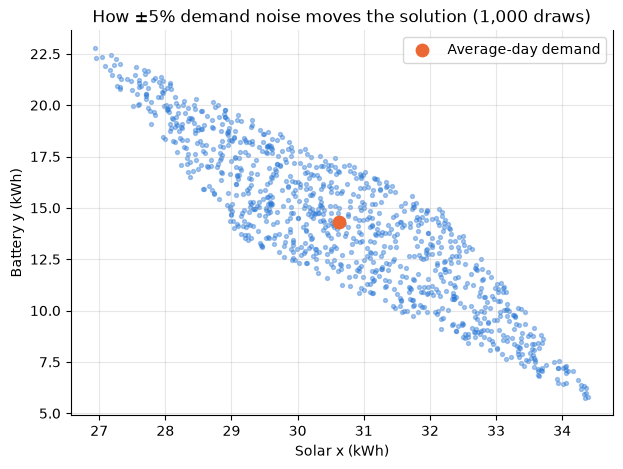

In [14]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(answers[0], answers[1], s=8, alpha=0.4, color=BLUE)
ax.scatter([base_x], [base_y], s=80, color=ORANGE, label="Average-day demand")
ax.set_xlabel("Solar x (kWh)")
ax.set_ylabel("Battery y (kWh)")
ax.set_title("How ±5% demand noise moves the solution (1,000 draws)")
ax.legend()
plt.show()

On an average day, a ±5% wobble in demand moves **solar** by only about ±6% (worst case ~12%), but moves the
**battery** by about ±26% (worst case ~60%).

How does that fit a condition number of only 5.8? The condition number limits the change of the **whole answer
vector (x, y)**, measured by its overall size, to about 5.8 × the relative change in the demands. It doesn't promise
anything about each part on its own. The battery value (~14 kWh) is small next to solar (~31 kWh), so a swing of a few kWh
is a big *percentage* of it. It is also computed as the *difference* 4·D1 − 3·D2 of two larger numbers, and
differences of similar-sized numbers magnify relative errors.

**Practical meaning:** the solar plan is robust, but the battery plan is very sensitive to demand-meter errors. Keep a
safety margin on battery charge. This matches Task 5, where the battery was also the more volatile source.

## Findings & Limitations

**Findings.** The dispatch system is mathematically sound: the determinant (−5) guarantees exactly one answer each day,
and a condition number of about 5.8 means it is well-conditioned. On a typical day the centre draws about 30 kWh from
solar and 15 kWh from the battery, at an average cost of UGX 11,400 a day, or about **UGX 341,000 for the month**.

The most useful finding is that **4 of 30 days were physically impossible** to meet exactly: the equations demanded
negative battery energy. This happens whenever the critical-equipment load D2 is more than about 4/3 of the daytime
load D1. No combination of solar and battery then satisfies both constraints. Our NNLS strategy chose the closest
non-negative plan and reported a shortfall of 2–12 kWh on those days. That is energy the manager must find elsewhere
(a generator, as in the extension) or cover by switching off non-critical load.

The battery is by far the more volatile and more sensitive source (CV 0.70 against 0.16 for solar, and it swings about
±26% for a ±5% demand error). Because battery energy costs three times as much, it drives the cost swings: the dearest
day (day 23, UGX 22,100) used a lot of battery and cost four times the cheapest. Shifting flexible loads into daylight
hours would reduce both cost and battery stress.

**Limitations.** The two equations are a stylised model. Real dispatch is an optimisation with limits the equations
ignore: panel output depends on sunshine, and the battery has a capacity and a state of charge that carries over from
one day to the next. We treated each day independently. Demand was simulated and prices are illustrative, and the cost
of a shortfall is not counted. The timing results depend on the computer used.